# Introduction to Kalman Filter

Originally developed in 1960 by R.E. Kalman, the Kalman filter provides an optimal estimate of how a system is going to change given noisy measurements and imperfect knowledge about the system. The Kalman filter is similar to least squares in many ways, but is a **sequential estimation** process rather than a batch one. It can be thought as a recursive formulation of the least squares method when the whole set of observations is partitioned into single measurements. As consequence, it is ideal for real-time applications as it has the advantage of operating on a sequential basis, taking measurements and processing them as they are available.



## Sequential Estimation of a Static System 

To demonstrate how sequential estimation works, here we'll see how to estimate the state of a static system by repeating multiple measurements and fusing them into a single information. Imagine we need to measure the (constant) temperature of a body: in this case the system is the body, the unknown is its temperature. Since each measurement is affected by an unknown error, we decide to repeat the measurement process many times and to average the measurement to get their mean.

At the time of $k^{th}$ measurement the estimated value of the state is the average of all previously taken measurements:
$$ \hat{x}_{k}= \frac{1}{k} \left( y_{1}+ y_{2}+ \ldots + y_{k-1}+ y_{k} \right) = \frac{1}{k} \sum _{n=1}^{k} \left( y_{n} \right) $$


, where
- $ {y}_{k}  $ is the value of the $k^{th}$ measurement

- $ \hat{x}_{k} $ is the estimated value of the state after taking the measurement $ {y}_{k}  $

It can be demonstrated that:

$$ \hat{x}_{k}= \hat{x}_{k-1}+ \frac{1}{k} \left( y_{k}- \hat{x}_{k-1} \right) $$

From the above equation we can see that each estimate $\hat{x}_{k}$ depends on three factors: 

- the previous estimate $\hat{x}_{k-1}$,
- the new measurement $y_{k}$ and
- a weighting factor $1/k$, being $k$ the number of measurements

As we'll see later, this is one of the five equations characterizing the Kalman filter. It is called the **state update equation**; moreover, the weighting factor is called **Kalman gain** and defined as $K_k$:

$$ \hat{x}_{k}= \hat{x}_{k-1}+ K_k \left( y_{k}- \hat{x}_{k-1} \right) $$

So, the state update equation tells us how the estimate changes due to a new term (called **innovation**) which is nothing else than the residual of the new measurement multiplied by the Kalman gain, whose value in this case decreases as the number of measurements increase, limiting the impact on the newly calculated mean of each new incoming measurement.

Obviously, being this a recursive approach, we need an **initial guess** to start the process, which represents our first estimate of the unknown state.

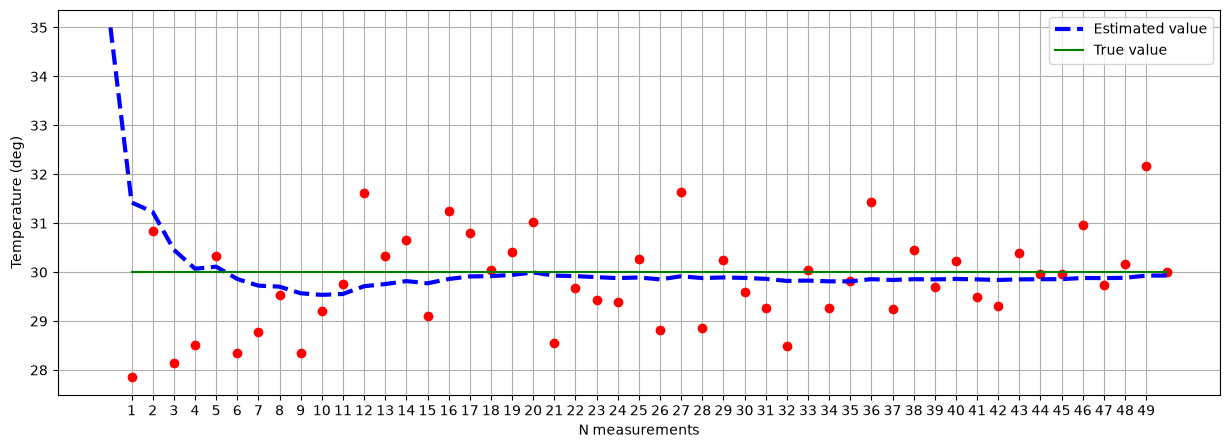

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
from estimation import *
########## meas model #############
trueTemp      = 30 # deg
oneSigma      = 1  # deg - uncertainty of the measuring device
nMeasurements = 50
###################################

########## input data #############
initialGuess  = 35 # deg 
###################################

static_estimator(trueTemp, oneSigma, nMeasurements, initialGuess)

### Moving average

The **moving average**, also known as the rolling mean, helps reduce noise and highlight significant patterns by averaging the last *n* data points over a specific window. It is used for smoothing variable time series data and identifying trends.

The Simple Moving Average (SMA) is calculated a follows:

$$  SMA_k=\frac{p_{n-k+1}+p_{n-k+2}+...+ p_n}{k}=\frac{1}{k}\sum_{i=n-k+1}^{n}p_{i} $$


In [2]:
import pandas as pd
%matplotlib widget
# importing time-series data
prices = pd.read_csv('Data/stockPrices.csv', index_col='Date', parse_dates=True)
# Printing dataFrame
prices.head()

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2016-07-21,507.192322,507.687622,497.781525,498.450195,485.688568,3097170.0
2016-07-22,498.276825,504.121429,497.831055,502.660278,489.790863,3184126.0
2016-07-25,502.239258,507.068512,498.945496,506.573181,493.603546,3803482.0
2016-07-26,506.697021,512.541626,502.833649,507.217102,494.231049,4853316.0
2016-07-27,506.721771,508.182922,499.737976,501.793488,488.946259,5090697.0


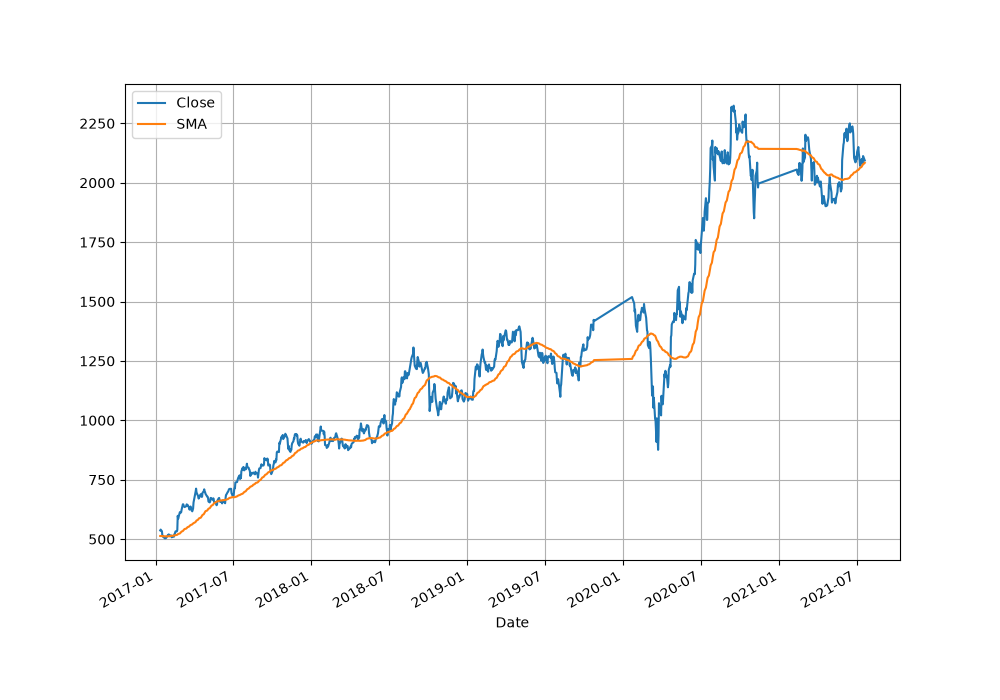

In [4]:
########## Input data ############
winDays = 60
##################################

# Extract 'Close' column and convert to DataFrame
prices = prices['Close'].to_frame()

# Calculate Simple Moving Average (SMA)
prices['SMA'] = prices['Close'].rolling(winDays).mean()

# plotting Close price and simple
prices.dropna(inplace=True)
void = prices[['Close', 'SMA']].plot(label='Closing prices', figsize=(10, 7), grid = True)

## Kalman Filter Implementation

The above approach is implemented in the Kalman filter that, for each available measurement, iterates across two phases:

•	the **prediction** phase, which implements equations that describe the physical model of our system: from the current state (and its uncertainty) we can then predict which will be the next one (and the relevant uncertainty)

•	the **correction** (or **update**) phase, which uses the new measurements to apply the needed correction to the predicted epoch state according with the confidence level we have (measurement uncertainty)

<center><img src="Images/kalmanFilterProcess.png" alt="Drawing" style="width: 400px;"/><center>




### The Prediction Phase
In this phase the system's dynamic model is implemented. Starting from the assumption that the Kalman filter is discrete (we estimate the state when new measurements are available and this happens at discrete time steps), the simplest assumption we can do is that the state at time $t_{k+1}$ is somewhat function of the state at the previous time $t_k$. We already defined this kind of relationship using the **state transition matrix**:

$$\mathbf{x}_{k+1}=\mathbf{\Phi}(t_{k+1},t_k) \mathbf{x}_k$$


Differently from the least squares method (when we just consider the measurement errors as the unique source of uncertainty in the estimation process), in the Kalman filter we consider the uncertainty around the state to estimate *during* the estimation itself. This means that, defined $\mathbf{P}_k$ the **state covariance matrix** at time $t_k$, is it also integrated along time and its value is then *predicted* at time $t_{k+1}$ :

$$\mathbf{P}_{k+1}=\mathbf{\Phi}(t_{k+1},t_k) \mathbf{P}_{k} \mathbf{\Phi}(t_{k+1},t_k)^T$$

So, the state transition matrix plays a big role in the prediction phase, where it is used to propagate both the state and its covariance *in between* measurements.

From a formal notation perspective, we need to discriminate between this phase and the successive (the update) one, so from now on we'll write these two equations as

$$ \begin{matrix}
\mathbf{x}_{k+1}^P=\mathbf{\Phi}_{t_k} \mathbf{x}_k \\
\mathbf{P}_{k+1}^P=\mathbf{\Phi}_{t_k} \mathbf{P}_{k}^P \mathbf{\Phi}_{t_k}^T \end{matrix}$$

, where the upperscript $P$ means that this is the *predicted* value, and $\mathbf{\Phi}_{t_k}$ is the state transition matrix from $k$ to $k+1$


The Correction (or Update) Phase
When a new measure is available, it is used to *correct* (or to *update*) the estimates calculated in the prediction phase. The state and its covariance matrix are updated as follow:

$$ \begin{matrix}
\mathbf{x}_{k+1} = \mathbf{x}_{k+1}^P +\mathbf{K}_{k+1} \left ( \mathbf{y}_{k+1}-\mathbf{H}_{k+1} \mathbf{x}_{k+1}^P\right ) \\
\mathbf{P}_{k+1}=\mathbf{P}_{k+1}^P - \mathbf{K}_{k+1} \mathbf{H}_{k+1} \mathbf{P}_{k+1}^P \end{matrix}$$

where

- $ \mathbf{x}_{k+1}^P $ is the predicted state at measurement time
- $ \mathbf{P}_{k+1}^P $ is the state covariance matrix at measurement time
- $ \mathbf{K}_{k+1}$ is the **Kalman gain**
- $\mathbf{y}_{k+1}-\mathbf{H}_{k+1} \mathbf{x}_{k+1}^P$ is the residual of the measurement $\mathbf{y}_{k+1}$, i.e. the difference between the observed and the modeled values of the measurement value
- $\mathbf{H}_{k+1}$ is the matrix which relates the state with the modeled observation (the same as the one used in the least square approach)

This equation tells us that, after a new measurement is available, <u>the predicted state estimate is modified by an amount which depends on the Kalman gain, which acts as a *moderator* between the measurement value and what is estimated by the model</u>. 

So, before using the above equations, we need to find the relevant Kalman gain, which value is: 

$$ \mathbf{K}_{k+1}=\mathbf{P}_{k+1}^P \mathbf{H}_{k+1}^T\left ( \mathbf{H}_{k+1} \mathbf{P}_{k+1}^P \mathbf{H}_{k+1}^T + \mathbf{R}_{k+1} \right )^{-1} $$

Differently from the previous example, when the Kalman gain was only function of the number of measurements taken up to that point, it depends on $\mathbf{R}_{k+1}$, which is the **measurement covariance matrix** (uncertainty) and on $ \mathbf{P}_{k+1} $ . The Kalman gain has the following characteristics:

- Its value can vary between 0 and 1
- It is small (close to 0) when $\mathbf{R}_{k+1}$ is large (high measurement noise) and/or $\mathbf{P}_{k+1}^P$ is small (low predicted state covariance)
- It is large (close to 1) when $\mathbf{R}_{k+1}$ is small (low measurement noise) and/or $\mathbf{P}_{k+1}^P$ is large (high predicted state covariance)


To summarize, the Kalman Filter is an **optimal filter**. It combines the prior state estimate with the measurement in a way that minimizes the uncertainty of the current state estimate.

<center><img src="Images/kalmanFilterProcess2.png" alt="Drawing" style="width: 900px;"/><center>

### Example - Sequential Estimation of a Static System with Kalman Filter

#### The dynamic model equations (prediction)
In this example we'll apply the Kalman filter equations to estimate (like in the previous case) the temperature of a body. In our case, since the problem is 1-dimensional, so all elements are scalar. The state is stationary, so the predicted state is the same as the current one:

$$ {x}_{k+1}^P = [1]{x}_{k} = {x}_{k}$$

The state transition matrix has unit value. Follows that:

$$ {p}_{k+1}^P = [1]{p}_{k}[1] = {p}_{k}$$

The first equation just says that the the predicted position at next step is the same as the the previous one (the object is stationary), while the second assumes that the predicted  estimate variance is equal to the current estimate variance (assuming the constant temperature model).

#### The state update equations (correction)
As first, we define how the Kalman gain evolves over time:

$$ k_{k+1}=\frac{p_{k+1}^P[1]}{[1]p_{k+1}^P[1] + r_{k+1}}=\frac{p_{k+1}^P}{p_{k+1}^P + r_{k+1}}$$

Here the matrix $\mathbf{H}$ has unit value since we are directly observing the body temperature, which is our unknown.

Once we know $ k_{k+1}$, we can calculate the updates to the state and its covariance estimates:

$$ x_{k+1}=x_{k+1}^P + K_{k+1}(y_{k+1}-x_{k+1}^P) $$

$$ p_{k+1}=p_{k+1}^P - K_{k+1}p_{k+1}^P= p_{k+1}^P(1-K_{k+1}) $$

For example, consider the following case:
- we're measuring the temperature with a device whose standard deviation $\sigma_d$ is 2 deg. Follows that $r = \sigma_d^2 = $ 4 $deg^2$
- we guess the temperature is 34 deg with standard deviation $\sigma_t$ equal to 3 deg. Follows that $p = \sigma_p^2 = $ 9 $deg^2$
- the true temperature value is 30 deg
- the first three measurements are 30.9, 28.7 and 29.3
- since the state to estimate is the temperature and we get temperature measurements, $ \mathbf{H} = 1$

Following the Kalman's filter steps we get:

- Step 1 ($k=0$)
  - $x_{1}^{P}= 1*x_{0} = 1*35 =35$
  - $p_{1}^{P}= 1*p_{0}*1 = 1*9*1 =9$
  - $k_{1}= \frac{p_0*1}{1*p_{0}*1+r_0} = \frac{9}{9+4} =0.692$
  - $x_{1}= x_{1}^{P} + k_{1}(y_1-x_{1}^{P})= 35 + 0.692*(30.9-35)= 32.163$
  - $p_{1}= p_{1}^{P}(1-k_{1})= 9*(1-0.692)= 2.772$
- Step 2 ($k=1$)
  - $x_{2}^{P}= 1*x_{1} = 1*32.163 =32.163$
  - $p_{2}^{P}= 1*p_{1}*1 = 1*2.772*1 =2.772$
  - $k_{2}= \frac{p_1*1}{1*p_{1}*1+r_1} = \frac{2.772}{2.772+4} =0.409$
  - $x_{2}= x_{2}^{P} + k_{2}(y_2-x_{2}^{P})= 32.163 + 0.409*(28.7-32.163)= 31.213$
  - $p_{2}= p_{2}^{P}(1-k_{2})= 2.772*(1-0.409)= 1.638$
- Step 3 ($k=3$)
  - $x_{3}^{P}= 1*x_{2} = 1*32.163 =31.213$
  - $p_{3}^{P}= 1*p_{2}*1 = 1*1.638*1 =1.638$
  - $k_{3}= \frac{p_2*1}{1*p_{2}*1+r_2} = \frac{1.638}{1.638+4} =0.291$
  - $x_{3}= x_{3}^{P} + k_{3}(y_3-x_{3}^{P})= 31.213 + 0.291*(29.3-31.213)= 30.656$
  - $p_{3}= p_{3}^{P}(1-k_{3})= 1.638*(1-0.291)= 1.161$

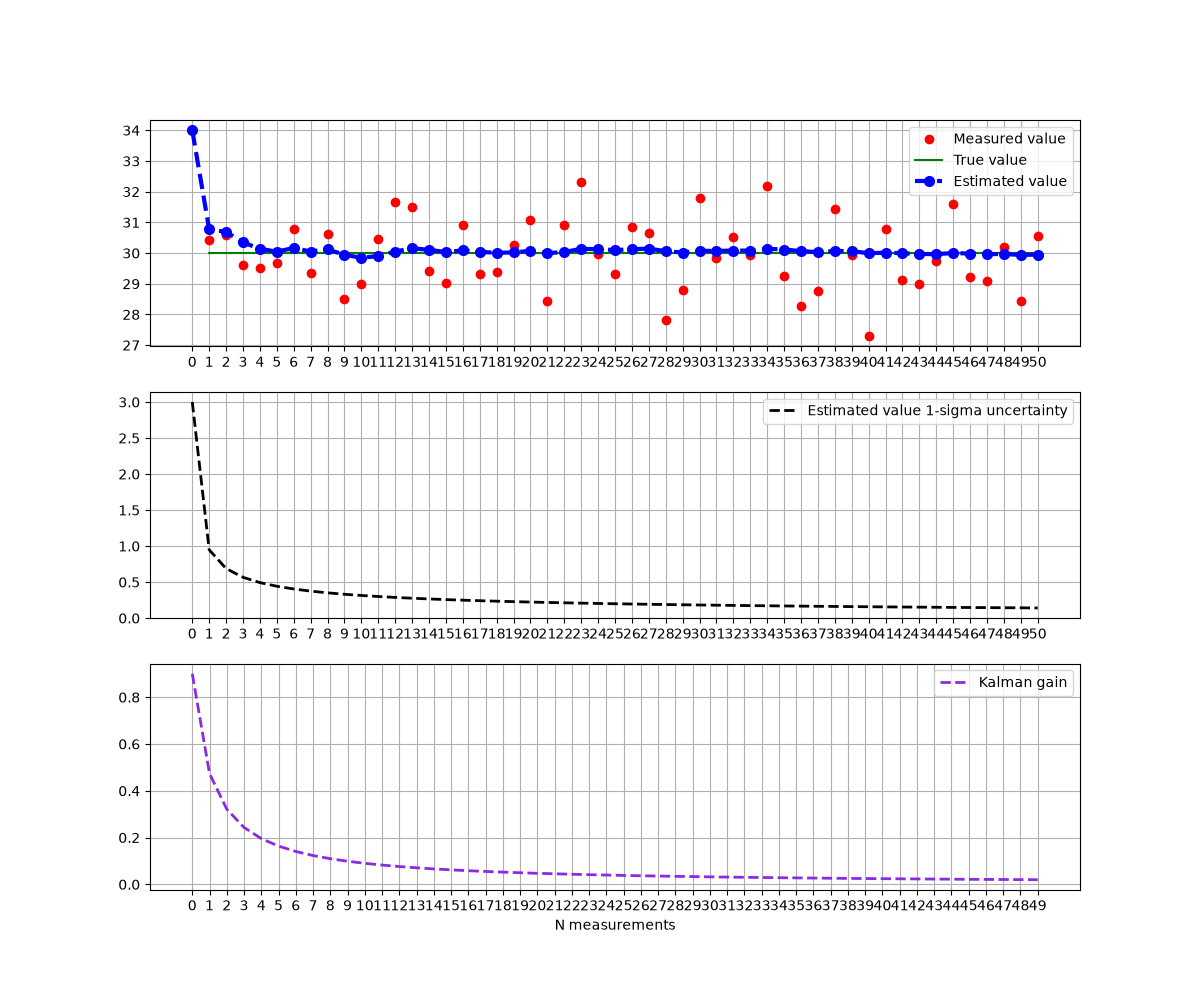

In [5]:
########## system model ###########
trueTemp      = 30 # °C
###################################

########## meas model #############
oneSigma      = 1  # °C - 1-sigma uncertainty of the measuring device (r = oneSigma^2)
###################################

########## input data #############
nMeasurements = 50
initialGuess  = 34     # °C 
initialUncertainty = 3 # °C - 1-sigma uncertainty of the initial guess
###################################

kalman_1d(trueTemp, oneSigma, nMeasurements, initialGuess, initialUncertainty)

Note as:

1) A low Kalman Gain (close to 0) means that the measurements have a small weight and **the filter gives more importance to the estimated values from the model**
2) An high Kalman gain (close to 1) means that the measure uncertainty is smaller than the overall state estimate uncertainty. Here **the filter gives an higher importance to the measurements** than the predicted value from the model

If the measurement uncertainty is equal to the estimate uncertainty, then the Kalman gain equals to 0.5.

<center><img src="Images/kalmanGain.png" alt="Drawing" style="width: 1100px;"/><center>


## Process Noise

Most of the times, when implementing an analytical model to describe how the system evolves over time, we define a *simplified* representation of the reality. For example, we ofter neglect the effect of the air drag while modelling the free fall of an heavy object, or we truncate the infinite number of armonics composing the Earth's gravitational field to a specific number. The net effect is that, due to our ignorance about the system or the difficult to properly model a part of it, we induce a *modelling error* that would eventually lead to completely wrong results.

To avoid such behaviour, we can consider the modelling errors as **process noise**, a random variable with its covariance that *fills* the gap between the model and the reality. Process noise is added on top of the 'deterministic' results of the modelling equations and makes them noisy, as it is a random value (with its covariance)


The process noise is taken into consideration by adding two extra terms ($\mathbf{w}$ and $\mathbf{Q}$) to the Kalman filter equations:

- $\mathbf{w}$ is the "noise" associated to our prediction model, and is meant to consider the non-modeled forces. If we are tracking the trajectory of a projectile, and our model assumes it is in vacuum, then the effect of air drag is process noise in this context. In Kalman filter $\mathbf{w}$ is assumed to be *white noise*, i.e., with zero mean

- $\mathbf Q$ equals the expected value of the noise $w$, computed as $\mathbf Q = \mathbb E[\mathbf{ww}^\mathsf T]$, and the process to derive it can be quite demanding

The true state evolves as $\mathbf{x}_{k+1}=\mathbf{\Phi}_{t_k} \mathbf{x}_k + \mathbf{w}_k$. Since $\mathbf{w}_k$ is zero-mean and unknown, the filter cannot add it to the predicted state: it accounts for it by inflating the predicted covariance with $\mathbf{Q}$.

-- **Prediction** 
$$ \begin{matrix}
\mathbf{x}_{k+1}^P=\mathbf{\Phi}_{t_k} \mathbf{x}_k\\
\mathbf{P}_{k+1}^P=\mathbf{\Phi}_{t_k} \mathbf{P}_{k}^P \mathbf{\Phi}_{t_k}^T + \mathbf{Q}_{k+1}\end{matrix}$$

-- **Update**

$$ \begin{matrix}
 \mathbf{K}_{k+1}=\mathbf{P}_{k+1}^P \mathbf{H}_{k+1}^T\left ( \mathbf{H}_{k+1} \mathbf{P}_{k+1}^P \mathbf{H}_{k+1}^T + \mathbf{R}_{k+1} \right )^{-1} \\
 \mathbf{P}_{k+1}=\mathbf{P}_{k+1}^P - \mathbf{K}_{k+1} \mathbf{H}_{k+1} \mathbf{P}_{k+1}^P \\
 \mathbf{x}_{k+1} = \mathbf{x}_{k+1}^P +\mathbf{K}_{k+1} \left ( \mathbf{y}_{k+1}-\mathbf{H}_{k+1} \mathbf{x}_{k+1}^P\right )
\end{matrix}$$


- $\mathbf{x}$: state vector
- $\mathbf{\Phi}$: state transition matrix
- $\mathbf{w}$: process noise
- $\mathbf{P}$: state covariance matrix
- $\mathbf{Q}$: process noise covariance matrix
- $\mathbf{K}$: Kalman gain
- $\mathbf{R}$: measurement covariance matrix
- $\mathbf{H}$: state to measurement matrix
- $\mathbf{y}$: measurements vector





In the example below we consider again the measurement of the temperature of a body at rest. This time we also imagine that the temperature is increasing due to some external effect which is not modeled in the state transition matrix, which is designed to model a stationary process. The following considerations apply:

- If $\mathbf{w}=\mathbf{Q}=0$ the process noise is not considered. The filter's estimate will diverge from the true temperature value since the measurements don't fit the model anymore
- If $\mathbf{w}\neq 0, \mathbf{Q}=0$ we add noise to the prediction model. The divergence's rate respect to the true temperature decreases while $\mathbf{w}$ increases
- If $\mathbf{w}= 0, \mathbf{Q}\neq 0$ we inflate the process noise covariance matrix. A fixed offset (called **lag error**) will be reached for a large number of measurements. The bigger the $\mathbf{Q}$ the smaller the lag error

A large value of process noise inflates the overall uncertainty around the solution, even if it is correctly estimated

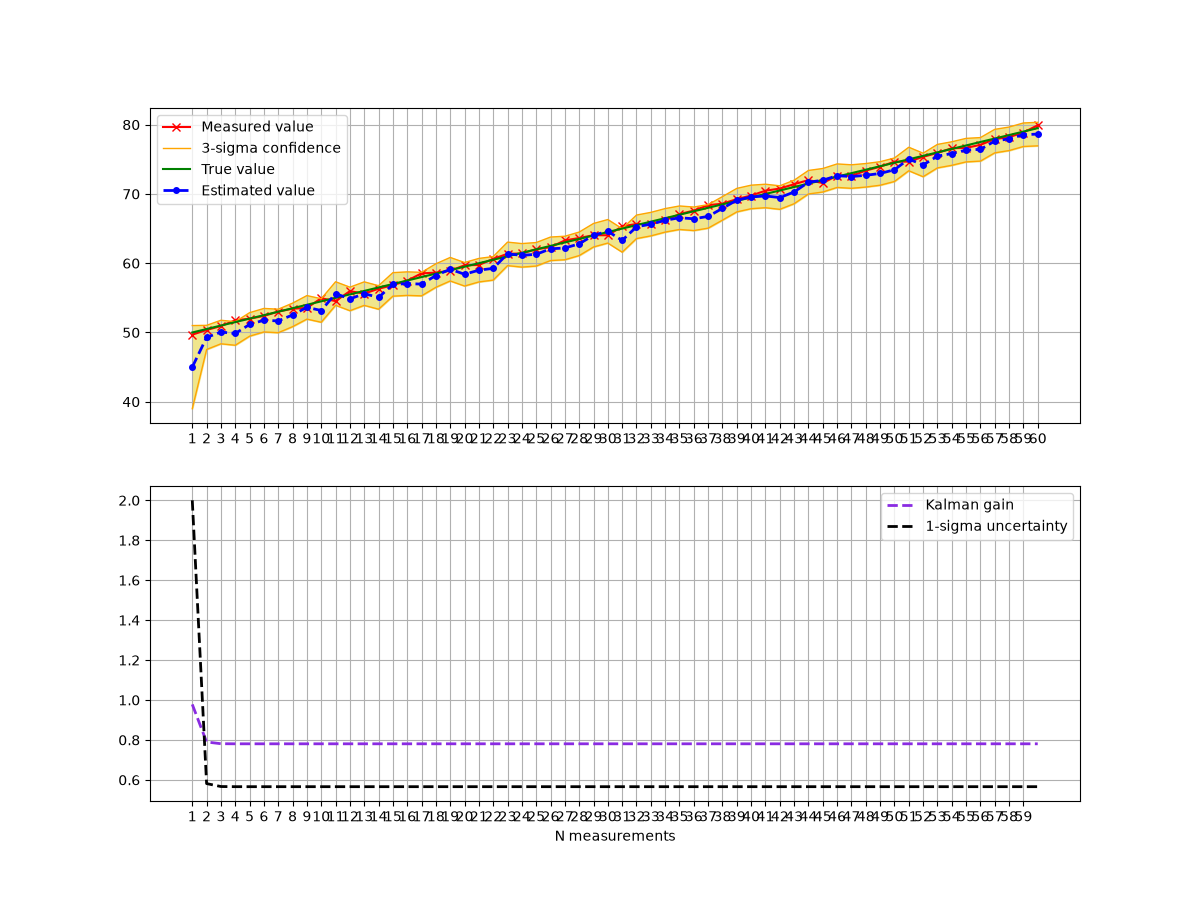

In [6]:
######### system model ############
initTemp     = 50  # deg
gradientTemp = 0.1 # deg/sec

########## meas model #############
oneSigma      = 0.3   # deg - 1-sigma uncertainty of the measuring device (oneSigma*oneSigma = r)
nMeasurements = 60
timeStep      =   5   # sec - time between measurements
###################################

########## input data #############
initialGuess       = 45     # °C
initialUncertainty = 2      # °C - 1-sigma uncertainty of the initial state
w                  = 0.5   # °C   std of the random-walk process noise acting on the true temperature
q                  = 0.25  # °C^2 process noise variance assumed by the filter
###################################

##### Use cases #####
## w = 0,   q = 0     -> the filter trusts the constant model: the lag error keeps growing
## w = 0,   q = 0.001 -> large lag error
## w = 0,   q = 0.005 -> Small lag error
## w = 0.5, q = 0.25  -> the filter's q matches the true process noise variance (q = w^2)
kalman_process_noise(initTemp, gradientTemp, oneSigma, nMeasurements, timeStep, initialGuess, initialUncertainty, w, q)

## Process Noise Covariance Matrix

The way how $\mathbf{Q}$ is chosen is one of the most complex process in designing Kalman filters. It depends on the dynamics of the system to simulate and how the model itself is modeled. In case of continous noise assumption, since the noise is changing continuously we will need to integrate over the chosen interval. It can be demnstrated that he equation for the discretization of the noise is:

$$\mathbf Q = \int_0^{\Delta t} \mathbf F(t)\mathbf{Q_c}\mathbf F^\mathsf{T}(t) dt$$

where $\mathbf{Q_c}$ is the continuous noise.


For a newtonian system where the noise affects the acceleration only the $\mathbf F(t)$ and $\mathbf Q_c$ matrice are:

$$F = \begin{bmatrix}1 & \Delta t & {\Delta t}^2/2 \\ 0 & 1 & \Delta t\\ 0& 0& 1\end{bmatrix}$$


$$\mathbf{Q_c} = s_d \begin{bmatrix}0&0&0\\0&0&0\\0&0&1\end{bmatrix}$$

, where $s_d$ is the **spectral density**, the scalar variable that can be tuned to add or remove process noise from the system model. The result is:

$$ \mathbf{Q} = s_d \begin{bmatrix}
\frac{\Delta t^5}{20} &  \frac{\Delta t^4}{8} &  \frac{\Delta t^3}{6}\\
\frac{\Delta t^4}{8} &  \frac{\Delta t^3}{3} &  \frac{\Delta t^2}{2}\\
\frac{\Delta t^3}{6} &  \frac{\Delta t^2}{2} &  \Delta t \end{bmatrix} $$



In practice, it is often chosen as a simple diagonal matrix and its elements are determined by trial and error. Although this method can be effective for a particular estimation scenario, such a process noise matrix is not generally applicable to other scenarios. 

